Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

Load Dataset

In [ ]:
df = pd.read_csv("insurance_40000_clean.csv")

df.head()

,Age,Gender,Annual_Income,Marital_Status,City,Occupation,Smoker,Existing_Disease,Dependents,Policy_Term_Years,Health_Score,Premium_Amount,Insurance_Taken,Policy_Status
0,22,Female,1018618,Married,Chennai,Accountant,No,No,5,10,93.6,16627.54,Yes,Active
1,59,Female,856094,Divorced,Delhi,Private Employee,No,No,0,2,92.5,14495.68,Yes,Expired
2,52,Male,202182,Married,Jaipur,Software Developer,No,No,5,10,84.3,23421.06,No,Not Purchased
3,41,Female,460340,Married,Vadodara,Student,No,No,2,10,100.0,15636.25,No,Not Purchased
4,40,Female,621088,Married,Jaipur,Teacher,Yes,No,4,2,86.7,19622.46,Yes,Active


Basic Dataset Checking

In [ ]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nNull Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Shape: (40000, 14)

Columns:
Index(['Age', 'Gender', 'Annual_Income', 'Marital_Status', 'City',
       'Occupation', 'Smoker', 'Existing_Disease', 'Dependents',
       'Policy_Term_Years', 'Health_Score', 'Premium_Amount',
       'Insurance_Taken', 'Policy_Status'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                40000 non-null  int64  
 1   Gender             40000 non-null  object 
 2   Annual_Income      40000 non-null  int64  
 3   Marital_Status     40000 non-null  object 
 4   City               40000 non-null  object 
 5   Occupation         40000 non-null  object 
 6   Smoker             40000 non-null  object 
 7   Existing_Disease   40000 non-null  object 
 8   Dependents         40000 non-null  int64  
 9   Policy_Term_Years  40000 non-null  int64  
 10 

──────── DATA PREPROCESSING ────────



Remove Duplicate Rows

In [ ]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (40000, 14)


Target Distribution

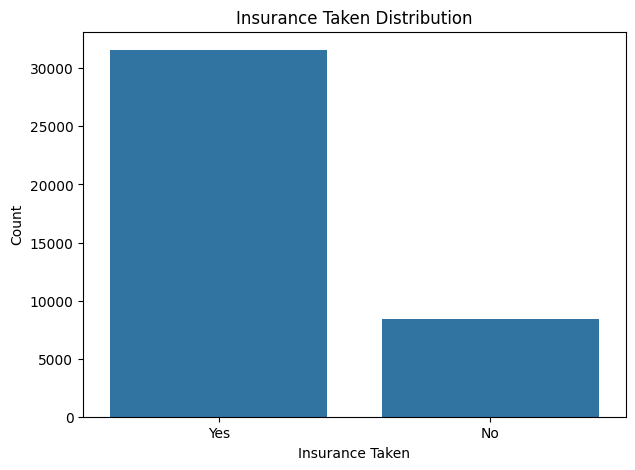

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Insurance_Taken")

plt.title("Insurance Taken Distribution")
plt.xlabel("Insurance Taken")
plt.ylabel("Count")

plt.show()

Remove Data Leakage Column

In [ ]:
df = df.drop(columns=["Policy_Status"])

Separate Features and Target

In [ ]:
X = df.drop("Insurance_Taken", axis=1)

y = df["Insurance_Taken"]

In [ ]:
columns_before_removing = df.columns.tolist()
print("Columns Before Removing:")
print(columns_before_removing)

# Remove Policy_Status if it exists
if "Policy_Status" in df.columns:
    df = df.drop(columns=["Policy_Status"])

# After removing
print("\nColumns After Removing:")
print(df.columns.tolist())

# See dataset shape
print("\nDataset Shape After Removing:")
print(df.shape)

# Display first 5 rows
print("\nFirst 5 Rows:")
print(df.head())

Columns Before Removing:
['Age', 'Gender', 'Annual_Income', 'Marital_Status', 'City', 'Occupation', 'Smoker', 'Existing_Disease', 'Dependents', 'Policy_Term_Years', 'Health_Score', 'Premium_Amount', 'Insurance_Taken']

Columns After Removing:
['Age', 'Gender', 'Annual_Income', 'Marital_Status', 'City', 'Occupation', 'Smoker', 'Existing_Disease', 'Dependents', 'Policy_Term_Years', 'Health_Score', 'Premium_Amount', 'Insurance_Taken']

Dataset Shape After Removing:
(40000, 13)

First 5 Rows:
   Age  Gender  Annual_Income Marital_Status      City          Occupation  \
0   22  Female        1018618        Married   Chennai          Accountant   
1   59  Female         856094       Divorced     Delhi    Private Employee   
2   52    Male         202182        Married    Jaipur  Software Developer   
3   41  Female         460340        Married  Vadodara             Student   
4   40  Female         621088        Married    Jaipur             Teacher   

  Smoker Existing_Disease  Dependents

In [ ]:
print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Features (X):
   Age  Gender  Annual_Income Marital_Status      City          Occupation  \
0   22  Female        1018618        Married   Chennai          Accountant   
1   59  Female         856094       Divorced     Delhi    Private Employee   
2   52    Male         202182        Married    Jaipur  Software Developer   
3   41  Female         460340        Married  Vadodara             Student   
4   40  Female         621088        Married    Jaipur             Teacher   

  Smoker Existing_Disease  Dependents  Policy_Term_Years  Health_Score  \
0     No               No           5                 10          93.6   
1     No               No           0                  2          92.5   
2     No               No           5                 10          84.3   
3     No               No           2                 10         100.0   
4    Yes               No           4                  2          86.7   

   Premium_Amount  
0        16627.54  
1        14495.68  
2        234

Encode All Categorical Columns

In [ ]:
label_encoder = LabelEncoder()

categorical_columns = X.select_dtypes(include="object").columns

for column in categorical_columns:
    X[column] = label_encoder.fit_transform(X[column])


In [ ]:
y = LabelEncoder().fit_transform(y)

Encode All Categorical Columns Prints

In [ ]:
print(X.head())

print("\nEncoded Target:")
print(pd.Series(y).value_counts())

   Age  Gender  Annual_Income  Marital_Status  City  Occupation  Smoker  \
0   22       0        1018618               1     2           0       0   
1   59       0         856094               0     3           6       0   
2   52       1         202182               1     5           7       0   
3   41       0         460340               1    11           8       0   
4   40       0         621088               1     5           9       1   

   Existing_Disease  Dependents  Policy_Term_Years  Health_Score  \
0                 0           5                 10          93.6   
1                 0           0                  2          92.5   
2                 0           5                 10          84.3   
3                 0           2                 10         100.0   
4                 0           4                  2          86.7   

   Premium_Amount  
0        16627.54  
1        14495.68  
2        23421.06  
3        15636.25  
4        19622.46  

Encoded Target:
1  

Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (32000, 12)
Testing Data: (8000, 12)


──────── MODEL TRAINING **────────**

Feature Scaling  in algorithm

*   Logistic Regression
*   KNN
*   SVM
*   Naive Byes





In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

Algorithm 1: Logistic Regression

In [ ]:
logistic_model = LogisticRegression(max_iter=5000)

logistic_model.fit(X_train_scaled, y_train)

y_pred_logistic = logistic_model.predict(X_test_scaled)

Evalution

In [ ]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_logistic))

print("Precision:",
      precision_score(y_test, y_pred_logistic, pos_label=1))

print("Recall:",
      recall_score(y_test, y_pred_logistic, pos_label=1))

print("F1 Score:",
      f1_score(y_test, y_pred_logistic, pos_label=1))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=['No', 'Yes']
))

Accuracy: 0.78925
Precision: 0.78925
Recall: 1.0
F1 Score: 0.8822132178286992

Classification Report:

              precision    recall  f1-score   support

          No       0.00      0.00      0.00      1686
         Yes       0.79      1.00      0.88      6314

    accuracy                           0.79      8000
   macro avg       0.39      0.50      0.44      8000
weighted avg       0.62      0.79      0.70      8000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Confusion Matrix

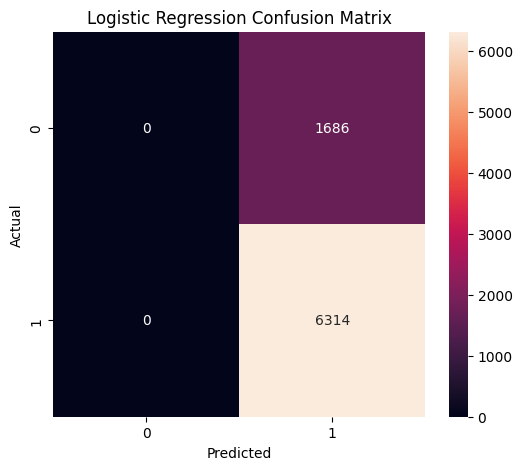

In [ ]:
cm = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Algorithm 2: Decision Tree

In [ ]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

y_pred_dt = decision_tree_model.predict(X_test)

Evalution

In [ ]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_dt))

print("Precision:",
      precision_score(y_test, y_pred_dt))

print("Recall:",
      recall_score(y_test, y_pred_dt))

print("F1 Score:",
      f1_score(y_test, y_pred_dt))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_dt
))

Accuracy: 0.699125
Precision: 0.8235878747722378
Recall: 0.7874564459930313
F1 Score: 0.805116994575338

Classification Report:

              precision    recall  f1-score   support

           0       0.32      0.37      0.34      1686
           1       0.82      0.79      0.81      6314

    accuracy                           0.70      8000
   macro avg       0.57      0.58      0.57      8000
weighted avg       0.72      0.70      0.71      8000



Confusion Matrix

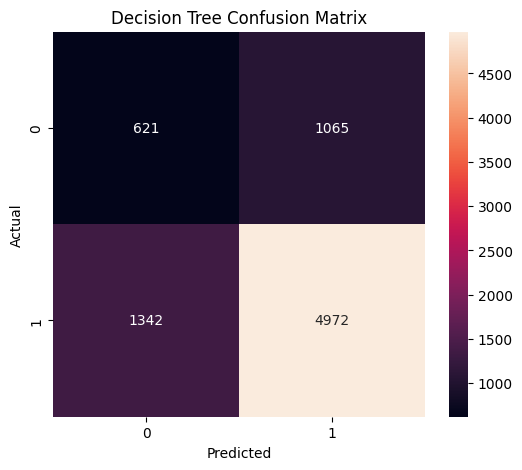

In [ ]:
cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Algorithm 3: Random Forest

In [ ]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

Evalution

In [ ]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Precision:",
      precision_score(y_test, y_pred_rf))

print("Recall:",
      recall_score(y_test, y_pred_rf))

print("F1 Score:",
      f1_score(y_test, y_pred_rf))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_rf
))

Accuracy: 0.82775
Precision: 0.821186881832379
Recall: 0.9993664871713652
F1 Score: 0.9015573653379054

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.19      0.31      1686
           1       0.82      1.00      0.90      6314

    accuracy                           0.83      8000
   macro avg       0.90      0.59      0.61      8000
weighted avg       0.86      0.83      0.78      8000



Confession Metrix

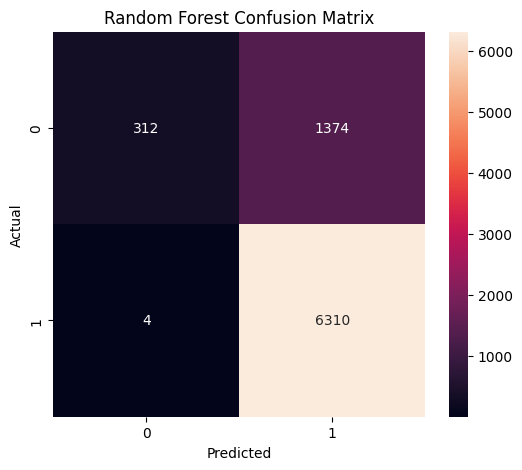

In [ ]:
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Algorithm 4: K-Nearest Neighbors (KNN)

In [ ]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
print("")

Evalution

In [ ]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_knn))

print("Precision:",
      precision_score(y_test, y_pred_knn))

print("Recall:",
      recall_score(y_test, y_pred_knn))

print("F1 Score:",
      f1_score(y_test, y_pred_knn))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_knn
))

Accuracy: 0.7785
Precision: 0.8080575149213239
Recall: 0.9434589800443459
F1 Score: 0.8705246237030542

Classification Report:

              precision    recall  f1-score   support

           0       0.43      0.16      0.23      1686
           1       0.81      0.94      0.87      6314

    accuracy                           0.78      8000
   macro avg       0.62      0.55      0.55      8000
weighted avg       0.73      0.78      0.74      8000



Confusion Metrix

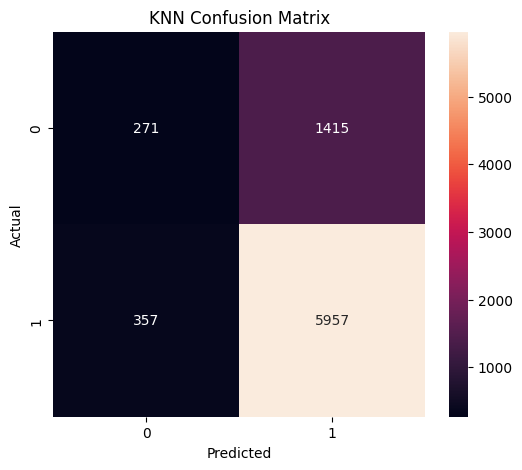

In [ ]:
cm = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Algorithm 5: Support Vector Machine (SVM)

In [ ]:
svm_model = SVC(
    kernel="linear"
)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

Evaluation

In [ ]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_svm))

print("Precision:",
      precision_score(y_test, y_pred_svm))

print("Recall:",
      recall_score(y_test, y_pred_svm))

print("F1 Score:",
      f1_score(y_test, y_pred_svm))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_svm
))

Accuracy: 0.78925
Precision: 0.78925
Recall: 1.0
F1 Score: 0.8822132178286992

Classification Report:

              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1686
           1       0.79      1.00      0.88      6314

    accuracy                           0.79      8000
   macro avg       0.39      0.50      0.44      8000
weighted avg       0.62      0.79      0.70      8000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Confusion Matrix

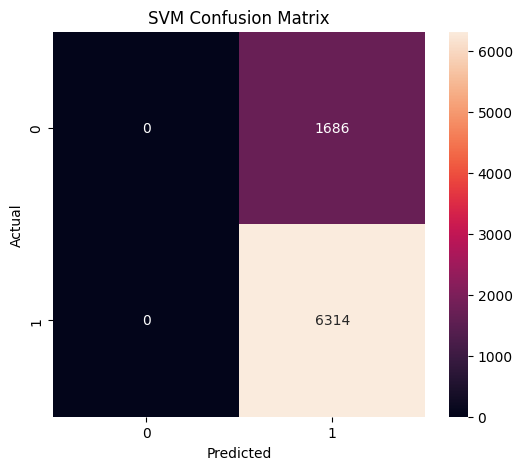

In [ ]:
cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Algorithm 6: Naive Bayes

In [ ]:
nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

y_pred_nb = nb_model.predict(X_test_scaled)

In [ ]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_nb))

print("Precision:",
      precision_score(y_test, y_pred_nb))

print("Recall:",
      recall_score(y_test, y_pred_nb))

print("F1 Score:",
      f1_score(y_test, y_pred_nb))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_nb
))

Accuracy: 0.802875
Precision: 0.8049439938200077
Recall: 0.9901805511561609
F1 Score: 0.8880051132732051

Classification Report:

              precision    recall  f1-score   support

           0       0.73      0.10      0.18      1686
           1       0.80      0.99      0.89      6314

    accuracy                           0.80      8000
   macro avg       0.77      0.55      0.53      8000
weighted avg       0.79      0.80      0.74      8000



Accuracy Comparison Graph

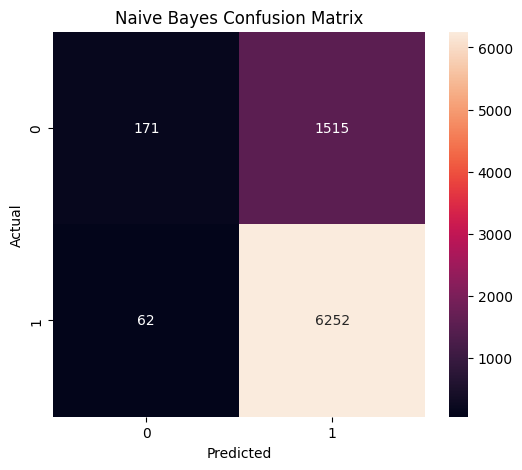

In [ ]:
cm = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Compare All **Algorithms**

In [ ]:
results = pd.DataFrame({

    "Algorithm": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM",
        "Naive Bayes"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_nb)
    ],

    "Precision": [
        precision_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_nb)
    ],

    "Recall": [
        recall_score(y_test, y_pred_logistic),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_nb)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_nb)
    ]
})

results = results.round(4)

print(results)

             Algorithm  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.7892     0.7892  1.0000    0.8822
1        Decision Tree    0.6991     0.8236  0.7875    0.8051
2        Random Forest    0.8278     0.8212  0.9994    0.9016
3                  KNN    0.7785     0.8081  0.9435    0.8705
4                  SVM    0.7892     0.7892  1.0000    0.8822
5          Naive Bayes    0.8029     0.8049  0.9902    0.8880


Accuracy Comparison Graph

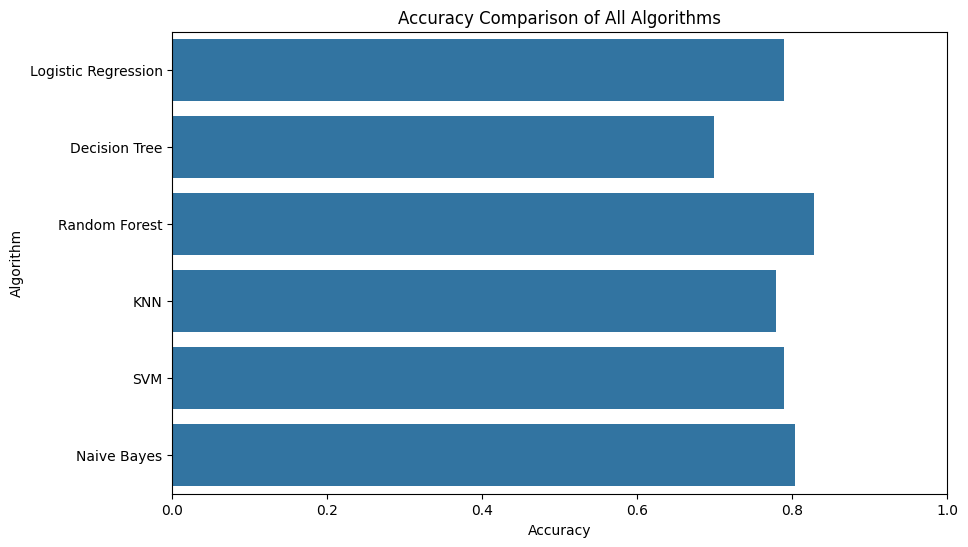

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="Accuracy",
    y="Algorithm"
)

plt.title("Accuracy Comparison of All Algorithms")

plt.xlim(0, 1)

plt.show()

F1-Score Comparison Graph

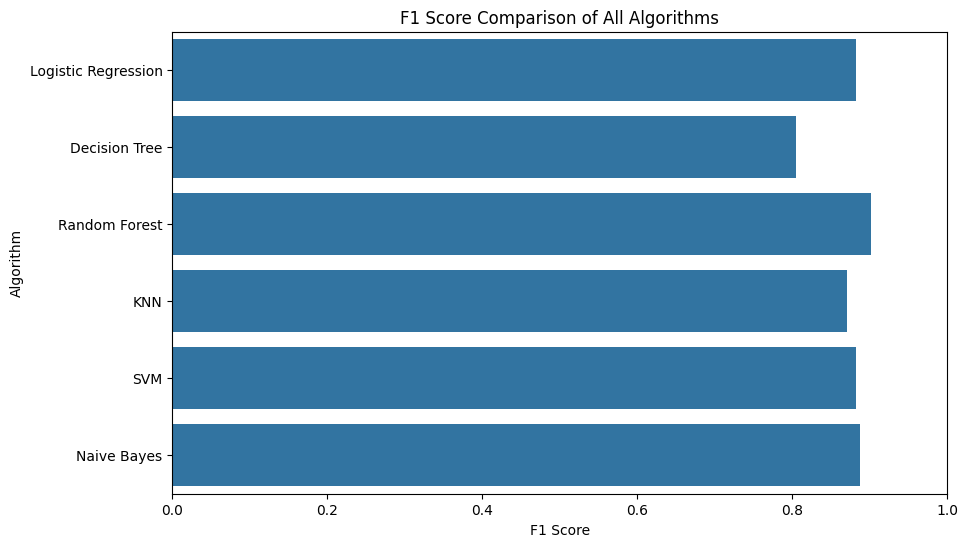

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="F1 Score",
    y="Algorithm"
)

plt.title("F1 Score Comparison of All Algorithms")

plt.xlim(0, 1)

plt.show()

Find the Best **Algorithm**

In [ ]:
best_model = results.loc[
    results["F1 Score"].idxmax()
]

print("Best Model:")
print(best_model)

Best Model:
Algorithm    Random Forest
Accuracy            0.8278
Precision           0.8212
Recall              0.9994
F1 Score            0.9016
Name: 2, dtype: object


Problem Statement 1: Insurance Taken Distribution Graph:-Cont Plot

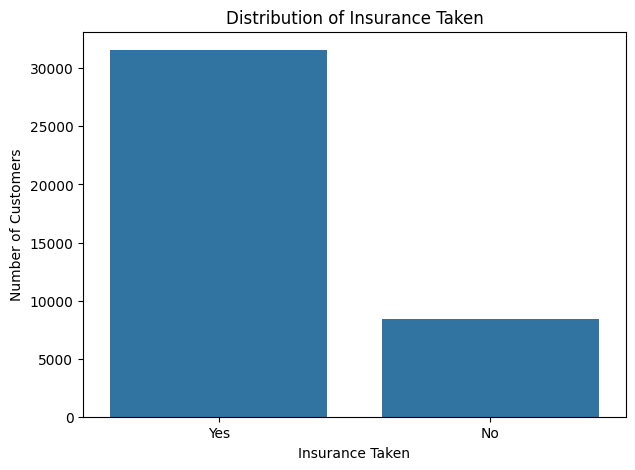

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Insurance_Taken"
)

plt.title("Distribution of Insurance Taken")
plt.xlabel("Insurance Taken")
plt.ylabel("Number of Customers")

plt.show()

Problem Statement 2: Analyze Occupation Distribution Graph :- Bar Graph



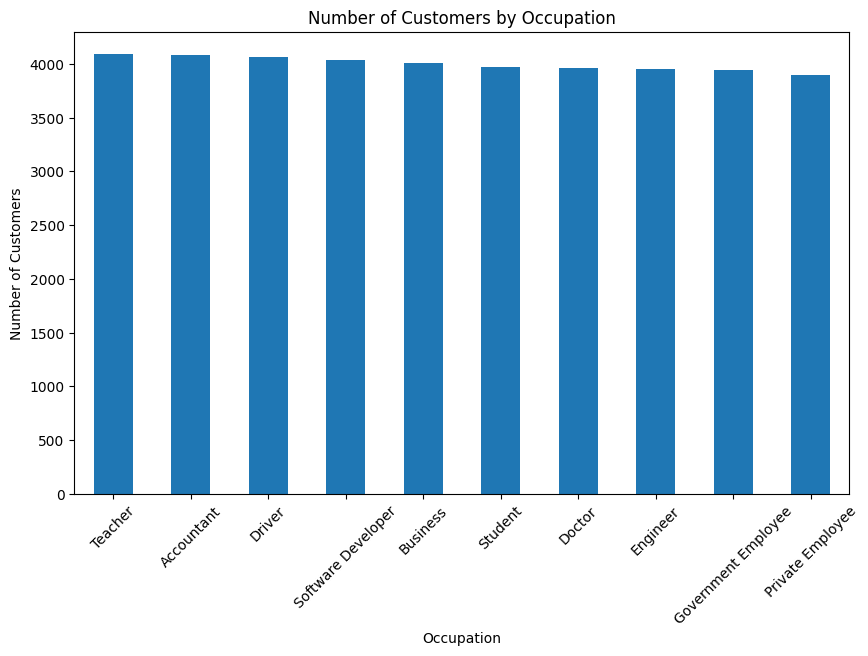

In [ ]:
plt.figure(figsize=(10, 6))

df["Occupation"].value_counts().plot(
    kind="bar"
)

plt.title("Number of Customers by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)

plt.show()

Problem Statement 3: Analyze Premium Amount by Smoker Status . Graph - BOX PLOT

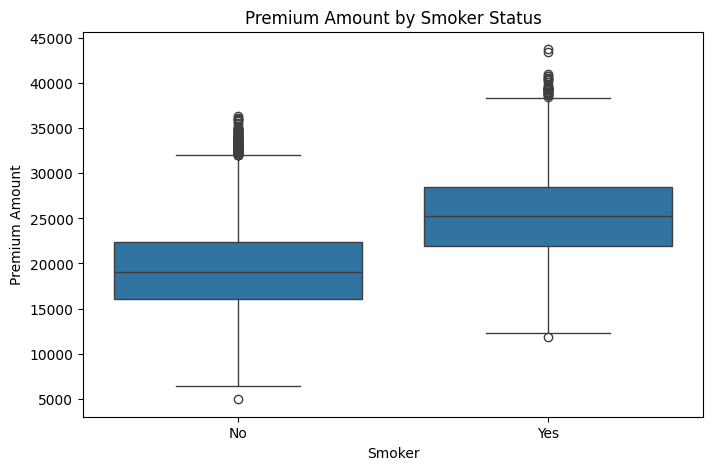

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Smoker",
    y="Premium_Amount"
)

plt.title("Premium Amount by Smoker Status")
plt.xlabel("Smoker")
plt.ylabel("Premium Amount")

plt.show()

Problem Statement :- 4

Analyze the percentage distribution of customers based on their marital status.
Graph :- Pie Chart

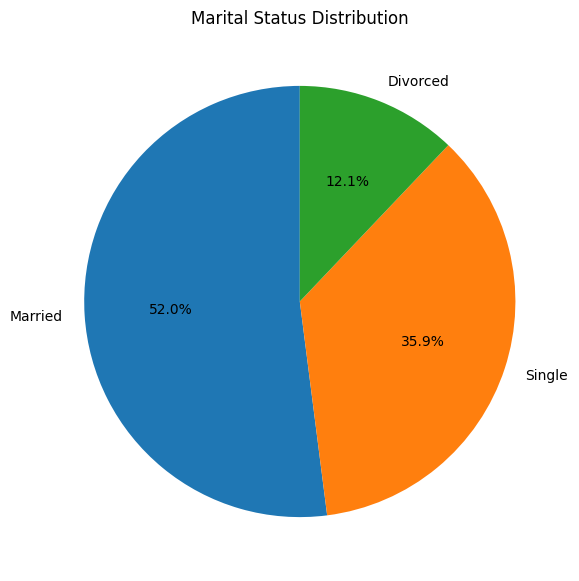

In [ ]:
marital_count = df["Marital_Status"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    marital_count.values,
    labels=marital_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Marital Status Distribution")

plt.show()

Problem Statement :-5

Analyze the percentage of customers who have taken an insurance policy and those who have not taken a policy.

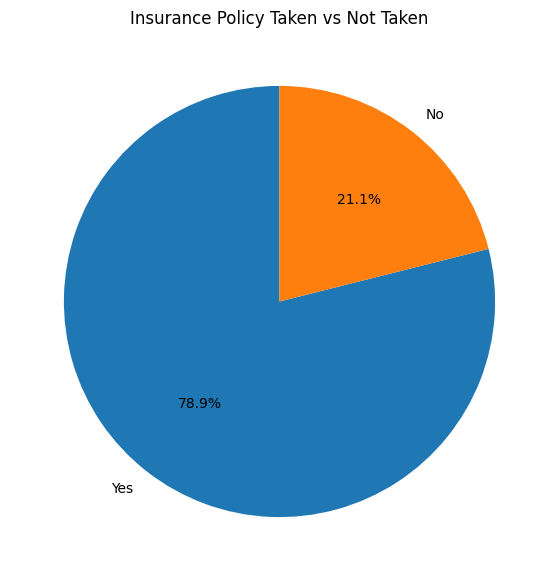

In [ ]:
policy_count = df["Insurance_Taken"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    policy_count.values,
    labels=policy_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Insurance Policy Taken vs Not Taken")

plt.show()

Problem Statement 6: Age vs Premium Amount

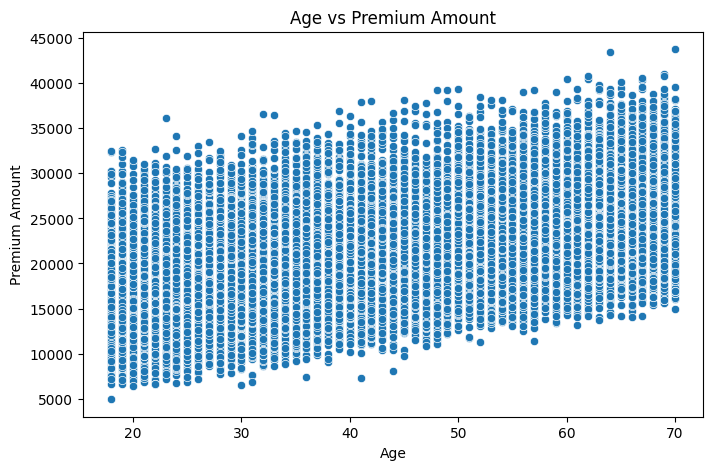

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Premium_Amount"
)

plt.title("Age vs Premium Amount")
plt.xlabel("Age")
plt.ylabel("Premium Amount")

plt.show()

Problem Statement 1: Analyze Annual Income Distribution. Graph :- Histogram

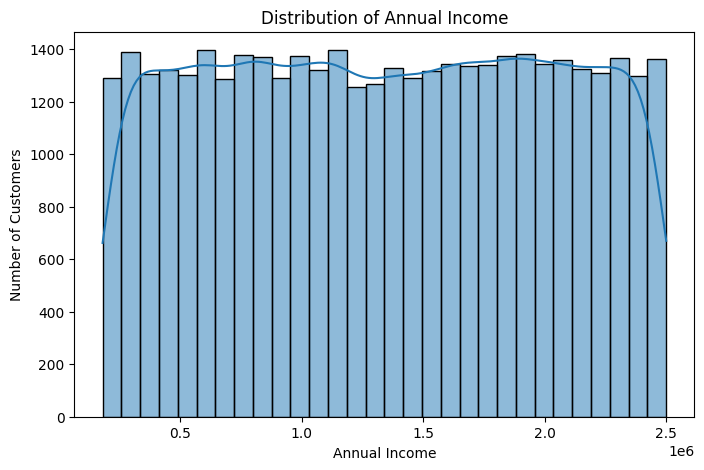

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Annual_Income",
    bins=30,
    kde=True
)

plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Number of Customers")

plt.show()